<p class="lead">Every unit so far has treated a molecule as a two-dimensional graph: atoms and bonds, with no coordinates. That abstraction is enough for most of cheminformatics, but it hides something real. A molecule is a physical object in three-dimensional space, and a flexible molecule is not one shape but a cloud of shapes that interconvert. This unit adds the third dimension. You will turn a flat SMILES string into 3-D coordinates, relax those coordinates with a force field, generate and prune an ensemble of conformations, align molecules on top of one another, and measure how similar two molecules are by shape rather than by connectivity. Everything here stays on the small molecule alone — no protein, no binding pocket. Structure-based methods that <em>do</em> involve the protein (docking, molecular dynamics) belong to the companion bioinformatics course (BGM324) and are deliberately out of scope; we say so again wherever the boundary is near.</p>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Explain what a conformer is, why a flexible molecule has many of them, and how degrees of freedom grow with rotatable bonds.</li>
<li>Generate 3-D coordinates from a SMILES string with distance geometry (ETKDG) and explain what the embedding does.</li>
<li>Describe a molecular-mechanics force field as a sum of bonded and non-bonded energy terms, and minimise a conformer with MMFF94 or UFF.</li>
<li>Build a conformer ensemble, rank it by energy, prune redundant shapes by RMSD, and reason about energy windows.</li>
<li>Align two molecules in 3-D (rigid Kabsch superposition and the field-based O3A method) and read the quality of the fit.</li>
<li>Compute ligand-based shape similarity (Gaussian-volume shape Tanimoto, alignment-free USR) and 3-D descriptors (principal moments of inertia, NPR shape triangle, radius of gyration, plane-of-best-fit, fraction of sp3 carbon).</li>
<li>Compare 3-D shape similarity with 2-D fingerprint similarity and explain when each is the right tool.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Run each code cell as you reach it and read the output before moving on. Green <strong>chemistry boxes</strong> define each chemical idea in plain language with an analogy a programmer already has. We build on earlier units: fingerprints and Tanimoto similarity from Unit 5, standardisation from Unit 4, data-curation habits from Unit 7, and the evaluation mindset throughout. The only library you must install in Google Colab is RDKit (<code>!pip install rdkit</code>); NumPy, pandas and matplotlib are already there. Keep an eye on one recurring warning: a conformer a force field likes is <em>not</em> necessarily the shape the molecule adopts when it binds a protein — the notebook returns to this several times, because it is the single most misunderstood point in ligand-based 3-D work.</p></div>

In [1]:
# Setup. In Google Colab, run once:  !pip install rdkit
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rdkit
from rdkit import Chem
from rdkit.Chem import AllChem, Draw, Descriptors, rdMolDescriptors, rdMolAlign, rdShapeHelpers
from rdkit.Chem.Draw import rdMolDraw2D
rdkit.RDLogger.DisableLog("rdApp.*")        # silence RDKit's valence/embedding chatter in this teaching notebook
np.random.seed(0)
SEED = 0xc0ffee                              # one random seed reused for every embedding, so the build is reproducible
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
# A small palette for drawing molecules in 3-D with matplotlib (element -> colour, radius).
ELEM = {"H": ("#dddddd", 18), "C": ("#444444", 46), "N": ("#2b5d9b", 50),
        "O": ("#c0392b", 50), "F": ("#27ae60", 42), "S": ("#d4ac0d", 60),
        "Cl": ("#27ae60", 60), "P": ("#e67e22", 62), "Br": ("#884ea0", 66)}
print("RDKit", rdkit.__version__, "| NumPy", np.__version__, "| flattening the world into 3-D")

RDKit 2026.03.4 | NumPy 2.4.6 | flattening the world into 3-D


## 1. From a flat graph to a shape in space

Units 2–15 represented a molecule as a <strong>graph</strong>: a set of atoms (nodes) joined by bonds (edges). A graph has no geometry — no angles, no distances, no left or right. That is a feature, not a bug: connectivity alone is enough to compute a formula, enumerate functional groups, hash a fingerprint and train most property models. But two facts the graph cannot express matter for biological activity.

First, a molecule occupies space. Its atoms sit at real 3-D coordinates, bond lengths and angles are fixed by chemistry, and the overall object has a <em>shape</em> — long and thin, flat and round, or compact and globular. A protein binding pocket is a 3-D cavity; whether a molecule fits is a question about shape, not connectivity.

Second, most drug-like molecules are <strong>flexible</strong>. Rotating around a single bond changes the molecule's shape without breaking any bond, so one connectivity corresponds to a whole family of 3-D shapes called <strong>conformers</strong> (or conformations). This is why "the 3-D structure of a molecule" is a slight fiction: a flexible molecule is a statistical ensemble of shapes that interconvert billions of times a second at body temperature.

<div class="box bridge"><h4>Chemistry box — conformer, rotatable bond, configuration</h4>
<p>A <strong>conformer</strong> is one 3-D arrangement of a molecule's atoms reachable from another by rotating around single bonds only — no bonds broken. A <strong>rotatable bond</strong> is a single, acyclic bond between two non-terminal heavy atoms; each one is roughly one internal degree of freedom. Do not confuse a conformation (same molecule, different shape — like a hand opening and closing) with a <em>configuration</em> (a different molecule requiring bond-breaking to interconvert — like your left and right hands, which is stereochemistry, Unit 3). A computer scientist can read a conformer as one point in a continuous "torsion-angle space" whose dimension is the number of rotatable bonds.</p></div>

The cell below makes the point concrete with <em>n</em>-butane (C–C–C–C). It has one meaningful rotatable bond (the central C–C), so its shape is controlled by a single torsion angle. We build two conformers that differ only in that angle — the stable <em>anti</em> form and a higher-energy <em>gauche</em> form — and draw the molecule three ways: as the flat graph, and as each 3-D conformer. We also define a small helper, <code>draw_conf_3d</code>, reused throughout the unit to render a conformer as a ball-and-stick picture in a matplotlib 3-D axis.

central C-C-C-C torsion:  anti  = -180.0 deg  |  gauche set to 60 deg


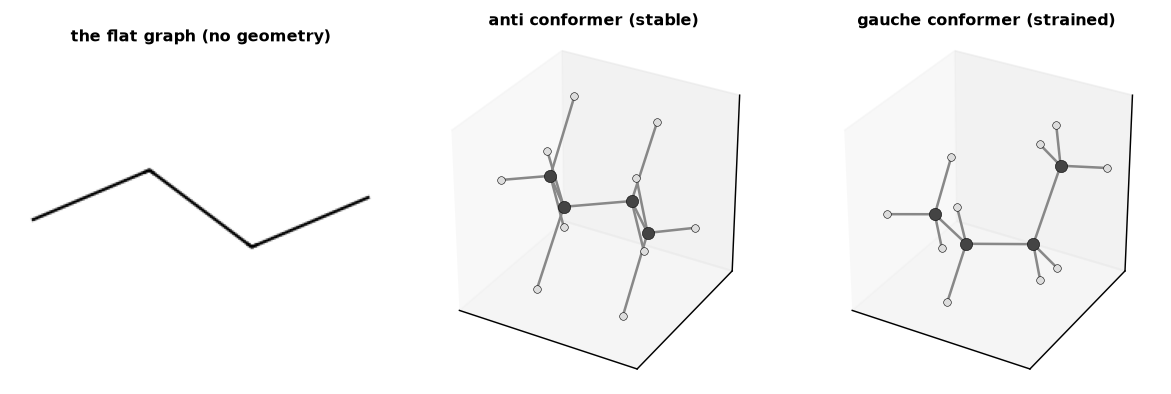

In [2]:
# A reusable helper: draw one conformer of a molecule into a matplotlib 3-D axis (ball-and-stick).
def draw_conf_3d(mol, ax, confId=0, title=""):
    conf = mol.GetConformer(confId)
    P = conf.GetPositions()                                   # (n_atoms, 3) array of xyz
    for b in mol.GetBonds():                                  # bonds as grey sticks
        i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
        ax.plot(*zip(P[i], P[j]), color="#888888", lw=1.4, zorder=1)
    for a in mol.GetAtoms():                                  # atoms as coloured balls
        c, s = ELEM.get(a.GetSymbol(), ("#000000", 40))
        ax.scatter(*P[a.GetIdx()], color=c, s=s, edgecolors="k", linewidths=0.3, zorder=2)
    ax.set_title(title, fontsize=9); ax.set_box_aspect((1, 1, 1))
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

butane = Chem.AddHs(Chem.MolFromSmiles("CCCC"))               # explicit H for a sensible geometry
AllChem.EmbedMolecule(butane, randomSeed=SEED); AllChem.MMFFOptimizeMolecule(butane)  # the anti minimum
idx = [a.GetIdx() for a in butane.GetAtoms() if a.GetSymbol() == "C"]   # the 4 carbons C0-C1-C2-C3
gauche = Chem.Mol(butane)
AllChem.SetDihedralDeg(gauche.GetConformer(), *idx, 60.0)     # force the central torsion to ~60 deg (gauche)
print("central C-C-C-C torsion:  anti  =",
      round(AllChem.GetDihedralDeg(butane.GetConformer(), *idx), 1), "deg  |  gauche set to 60 deg")
fig = plt.figure(figsize=(9.2, 3.0))
ax0 = fig.add_subplot(1, 3, 1); ax0.imshow(np.array(Draw.MolToImage(Chem.MolFromSmiles("CCCC"), size=(240, 200))))
ax0.axis("off"); ax0.set_title("the flat graph (no geometry)", fontsize=9)
draw_conf_3d(butane, fig.add_subplot(1, 3, 2, projection="3d"), title="anti conformer (stable)")
draw_conf_3d(gauche, fig.add_subplot(1, 3, 3, projection="3d"), title="gauche conformer (strained)")
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> One molecule, one graph, many shapes. <em>n</em>-butane's connectivity (left) fixes nothing about its geometry. Rotating the central C–C bond moves the two end carbons from the extended <em>anti</em> arrangement (middle, the energy minimum, torsion ≈ 180°) to the folded <em>gauche</em> arrangement (right, torsion 60°), where the terminal methyl groups crowd each other. Both are the same molecule — no bond was broken — yet they have different shapes and different energies. The grey sticks are bonds and the coloured balls are atoms (dark grey = carbon, pale = hydrogen). Everything the rest of this unit does begins from coordinates like these.</p>

<div class="box warn"><h4>A flat molecule is a model, not reality</h4><p>When you call <code>Chem.MolFromSmiles("CCCC")</code> you get a graph with <em>no</em> coordinates at all — not even 2-D ones until you ask for a depiction. The 2-D picture Units 1–15 draw is a readable layout, not a measurement. Real geometry only appears when you <em>embed</em> the molecule into 3-D, which is the next section. Forgetting this is how people accidentally compute a "3-D descriptor" on a molecule that has no 3-D coordinates and get zeros or nonsense.</p></div>

## 2. Generating 3-D coordinates: distance geometry and ETKDG

How does a program turn a connectivity graph into coordinates? The dominant approach is <strong>distance geometry</strong>. The idea is elegant for a computer scientist: instead of reasoning about angles, reason about the matrix of all pairwise atom–atom distances. Chemistry constrains that matrix tightly — a C–C single bond is ≈1.5 Å, a C=C is ≈1.3 Å, atoms three bonds apart are confined by the bond angles between them, and no two atoms may be closer than the sum of their van der Waals radii. The algorithm (i) builds upper and lower <em>bounds</em> on every pairwise distance from these rules, (ii) samples a random distance matrix inside the bounds, and (iii) finds the 3-D coordinates whose distances best match the sampled matrix (an eigen-decomposition, the "embedding"). The result is a rough 3-D structure that is then cleaned up. Throughout we start from a molecule written as a SMILES string<sup class="c"><a href="#r4">[4]</a></sup> and use the open-source RDKit toolkit<sup class="c"><a href="#r24">[24]</a></sup> for every step from parsing to descriptors.

Plain distance geometry produces geometries that are valid but often unrealistic — wrong ring puckers, implausible torsions. RDKit's default method, <strong>ETKDG</strong> (Experimental-Torsion Knowledge Distance Geometry), fixes this by adding <em>torsion-angle preferences</em> mined from thousands of crystal structures: it nudges the embedding towards torsions chemists actually observe.<sup class="c"><a href="#r1">[1]</a></sup> It is fast, needs no force field for the initial guess, and is the recommended starting point;<sup class="c"><a href="#r6">[6]</a></sup> the torsion knowledge was later refreshed.<sup class="c"><a href="#r23">[23]</a></sup> We use the version-3 parameters throughout.

<div class="box bridge"><h4>Chemistry box — what "embedding" means here</h4>
<p>"Embedding" is the same word a machine-learning engineer uses, and almost the same idea: map an object into a coordinate space so that geometric relations (here, distances) are preserved. The difference is that the target distances come from physical chemistry (bond lengths, angles, van der Waals radii) rather than from data, and the space is literal 3-D space. One important practical rule: <strong>add explicit hydrogens before embedding</strong> (<code>Chem.AddHs</code>). Hydrogens take up space and set the geometry around each atom; embedding the "heavy-atom-only" graph gives distorted shapes.</p></div>

parsed graph has 15 heavy atoms and NO conformers: 0
after AddHs: 33 atoms | embed status: 0 | conformers now: 1
first atom xyz: [-4.37  -0.805 -1.34 ] | bounding-box size (A): [10.15  4.03  6.04]


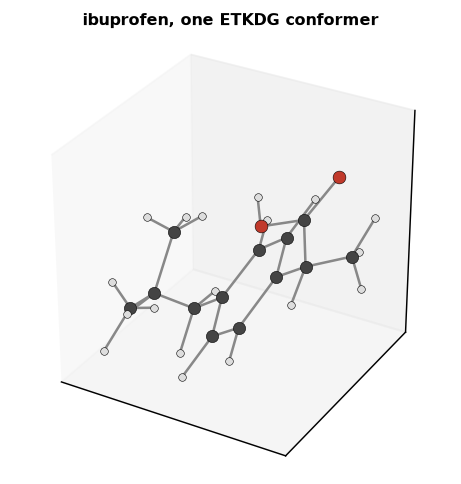

In [3]:
# Embed ibuprofen with ETKDG v3. Compare heavy-atom count, before/after coordinate existence.
smiles = "CC(C)Cc1ccc(C(C)C(=O)O)cc1"                 # ibuprofen, a common over-the-counter painkiller
mol_noH = Chem.MolFromSmiles(smiles)
print("parsed graph has", mol_noH.GetNumAtoms(), "heavy atoms and NO conformers:", mol_noH.GetNumConformers())
mol = Chem.AddHs(mol_noH)                              # add explicit H -> now 33 atoms
params = AllChem.ETKDGv3(); params.randomSeed = SEED
ok = AllChem.EmbedMolecule(mol, params)               # returns 0 on success; fills a conformer with xyz
print("after AddHs:", mol.GetNumAtoms(), "atoms | embed status:", ok, "| conformers now:", mol.GetNumConformers())
P = mol.GetConformer().GetPositions()
print("first atom xyz:", np.round(P[0], 3), "| bounding-box size (A):", np.round(P.max(0) - P.min(0), 2))
fig = plt.figure(figsize=(4.4, 3.8)); draw_conf_3d(mol, fig.add_subplot(projection="3d"),
                                                   title="ibuprofen, one ETKDG conformer")
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> An ibuprofen conformer produced by ETKDG. The printout shows the lifecycle: the parsed SMILES graph has no conformers (coordinate count zero); after adding explicit hydrogens and embedding, the molecule carries one conformer whose atoms have real coordinates, spanning a bounding box of roughly a nanometre on its longest side. The aromatic ring is flat, the sp3 carbons are tetrahedral, and the whole object is a believable physical shape — all inferred from connectivity plus the ETKDG torsion knowledge, with no experimental input.</p>

A quick sanity check before trusting any geometry: bond lengths and non-bonded contacts should sit in physically sensible ranges, or the embedding has failed silently.

In [4]:
# Sanity-check the embedded geometry: average bond lengths by element pair, and the closest contact.
conf = mol.GetConformer(); Pc = conf.GetPositions()
bylen = {}
for b in mol.GetBonds():
    i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
    pair = "-".join(sorted([mol.GetAtomWithIdx(i).GetSymbol(), mol.GetAtomWithIdx(j).GetSymbol()]))
    bylen.setdefault(pair, []).append(float(np.linalg.norm(Pc[i] - Pc[j])))
for pair in ["C-C", "C-H", "C-O", "H-O"]:
    if pair in bylen:
        print("%-4s mean %.3f A  (n=%d)" % (pair, np.mean(bylen[pair]), len(bylen[pair])))
D = np.linalg.norm(Pc[:, None] - Pc[None, :], axis=-1); np.fill_diagonal(D, np.inf)
for b in mol.GetBonds():                                    # mask out directly bonded (1,2) pairs
    D[b.GetBeginAtomIdx(), b.GetEndAtomIdx()] = D[b.GetEndAtomIdx(), b.GetBeginAtomIdx()] = np.inf
print("closest non-bonded atom pair: %.2f A  (a steric clash would be well under 1.5 A)" % D.min())

C-C  mean 1.444 A  (n=13)
C-H  mean 1.106 A  (n=17)
C-O  mean 1.328 A  (n=2)
H-O  mean 1.007 A  (n=1)
closest non-bonded atom pair: 1.76 A  (a steric clash would be well under 1.5 A)


The averages land where chemistry says they should: a carbon–carbon bond near 1.4–1.5 Å (aromatic bonds are a little shorter than sp3 single bonds, which pulls the mean down), a carbon–hydrogen bond near 1.1 Å, and a carbon–oxygen average near 1.3 Å — note this bucket blends the carboxyl group's short C=O double bond (~1.2 Å) with its longer C–OH single bond (~1.35 Å), so the mean sits between them rather than at a single canonical value, a reminder that averaging by element pair hides bond order. No two non-bonded atoms come closer than about 1.7 Å — the nearest contact is a geminal hydrogen pair, comfortably above a clash. A failed embedding would betray itself with absurd bond lengths or overlapping atoms; this short check is a cheap guard worth running on any batch of generated geometries, in the data-curation spirit of Unit 7.

## 3. Force fields and energy minimisation

An embedded conformer is a good guess, but its bond lengths and angles are only approximately right. To refine it we need a way to score a geometry's energy and to move atoms downhill. That is the job of a <strong>force field</strong>: a fast, classical approximation to a molecule's potential energy as an explicit function of atomic coordinates.

<div class="box bridge"><h4>Chemistry box — what a force field is</h4>
<p>A molecular-mechanics <strong>force field</strong> models a molecule as balls (atoms) joined by springs (bonds) and writes the total energy as a sum of simple terms: <em>bonded</em> terms that penalise stretched bonds, bent angles and twisted torsions, plus <em>non-bonded</em> terms for atoms not directly connected — van der Waals contact (the "don't overlap, but weakly attract" interaction of Unit 1) and electrostatics between partial charges. No quantum mechanics and no electrons are computed, which is why it is thousands of times faster than a real energy calculation and why it is only an approximation. For a programmer: it is a hand-crafted, differentiable loss function over atomic coordinates, and minimising it is gradient descent in 3<em>N</em> dimensions.</p></div>

We use two classical force fields. <strong>MMFF94</strong> (Merck Molecular Force Field) was parameterised against high-quality quantum-chemical data and is accurate for drug-like organic molecules;<sup class="c"><a href="#r2">[2]</a></sup> its open-source implementation in RDKit follows the published specification closely.<sup class="c"><a href="#r15">[15]</a></sup> <strong>UFF</strong> (Universal Force Field) trades some accuracy for coverage: it has parameters for the whole periodic table, so it is the fallback when MMFF lacks parameters for an exotic atom.<sup class="c"><a href="#r5">[5]</a></sup> "Minimising" a conformer means running an optimiser (RDKit uses a quasi-Newton method) until the forces on the atoms are near zero — a local energy minimum.

In [5]:
# Minimise the ibuprofen conformer and watch the energy fall. Compare MMFF94 vs UFF on the SAME start.
def mmff_energy(m, confId=0):
    props = AllChem.MMFFGetMoleculeProperties(m)
    return AllChem.MMFFGetMoleculeForceField(m, props, confId=confId).CalcEnergy()

m_mmff = Chem.Mol(mol)                                   # copies share the starting geometry
m_uff = Chem.Mol(mol)
e0 = mmff_energy(m_mmff)
AllChem.MMFFOptimizeMolecule(m_mmff, maxIters=2000)      # relax with MMFF94
AllChem.UFFOptimizeMolecule(m_uff, maxIters=2000)        # relax the same start with UFF
rows = [("start (ETKDG, unrefined)", round(e0, 2)),
        ("after MMFF94 minimisation", round(mmff_energy(m_mmff), 2)),
        ("after UFF minimisation (scored by MMFF)", round(mmff_energy(m_uff), 2))]
print(pd.DataFrame(rows, columns=["geometry", "MMFF energy (kcal/mol)"]).to_string(index=False))
rmsd = rdMolAlign.GetBestRMS(Chem.RemoveHs(m_mmff), Chem.RemoveHs(m_uff))
print("heavy-atom RMSD between the MMFF and UFF minima: %.3f A" % rmsd)

                               geometry  MMFF energy (kcal/mol)
               start (ETKDG, unrefined)                   52.21
              after MMFF94 minimisation                   23.79
after UFF minimisation (scored by MMFF)                   33.87
heavy-atom RMSD between the MMFF and UFF minima: 0.099 A


The printout reports the same geometry scored by one common yardstick (MMFF energy, in kilocalories per mole). Minimisation lowers the energy substantially from the raw ETKDG guess — the optimiser removes small bond-length and angle strains the embedding left behind. The two force fields relax to geometries that are close but not identical (a sub-ångström heavy-atom RMSD), because they disagree slightly on the ideal torsions and contacts. The lesson: an energy number is only meaningful <em>relative to the same force field</em>; never compare an MMFF energy with a UFF energy directly, just as you would never compare loss values from two different loss functions.

Minimisation is iterative gradient descent. The next cell gives the optimiser increasing iteration budgets and watches the energy fall, to make the "rolling downhill" picture concrete.

In [6]:
# Watch the energy fall as the optimiser is allowed more iterations (same starting conformer each time).
print("max iterations ->  MMFF energy (kcal/mol)   converged?")
for n in [0, 3, 10, 50, 500]:
    cpy = Chem.Mol(mol)
    flag = "(start)" if n == 0 else ("yes" if AllChem.MMFFOptimizeMolecule(cpy, maxIters=n) == 0 else "not yet")
    print("      %4d       %10.2f          %s" % (n, mmff_energy(cpy), flag))

max iterations ->  MMFF energy (kcal/mol)   converged?
         0            52.21          (start)
         3            36.52          not yet
        10            31.78          not yet
        50            26.10          not yet
       500            23.79          yes


The energy drops steeply in the first handful of iterations — the embedding's small strains are relieved almost immediately — then flattens as the optimiser approaches a local minimum, where the forces on the atoms vanish and further iterations change little. This is exactly the convergence curve of any gradient-based optimiser a machine-learning student has seen; the only difference is that the loss is a physical energy and the parameters are atomic coordinates.

<div class="box warn"><h4>Minimisation finds a <em>local</em> minimum, not the global one</h4><p>Gradient descent on the force-field energy rolls downhill to the nearest valley, which depends entirely on where you started. For a flexible molecule there are many valleys (many conformers), and one embedding + minimisation reaches only one of them. That is exactly why we do not stop at a single conformer but generate an <em>ensemble</em> — the subject of the next section.</p></div>

## 4. Conformer ensembles and energy windows

Because one embedding reaches one minimum, the standard practice is to generate <em>many</em> conformers from different random starts, minimise each, and keep a diverse, low-energy subset. RDKit's <code>EmbedMultipleConfs</code> does the generation; we then minimise every conformer and sort by energy. Two quantities organise the result.

The first is the <strong>energy window</strong>. Conformers much higher in energy than the lowest one are rarely populated at body temperature — the Boltzmann factor $e^{-\Delta E / RT}$ makes a conformer 3 kcal/mol above the minimum roughly 150-fold rarer than the minimum at 37 °C. A common rule of thumb keeps conformers within about 3–10 kcal/mol of the lowest; we use a window and watch how many survive.

The second is <strong>redundancy</strong>. Different random starts frequently converge to the same shape, so the raw ensemble contains near-duplicates. We remove them by heavy-atom <strong>RMSD</strong> (root-mean-square deviation after optimal superposition, Unit 6's distance idea applied to coordinates): conformers closer than a threshold are treated as the same shape. Pruning gives a small set of genuinely distinct, low-energy conformations — the ligand-based "ensemble" that downstream shape methods consume.<sup class="c"><a href="#r3">[3]</a></sup> How well different generators reproduce experimentally observed conformations has itself been benchmarked systematically.<sup class="c"><a href="#r16">[16]</a></sup>

In [7]:
# Generate a conformer ensemble for a flexible drug, minimise all, and tabulate energies relative to the minimum.
flex = Chem.AddHs(Chem.MolFromSmiles("CNCCC(Oc1ccc(C(F)(F)F)cc1)c1ccccc1"))   # fluoxetine (Prozac), 6 rotatable bonds
params = AllChem.ETKDGv3(); params.randomSeed = SEED; params.pruneRmsThresh = -1   # keep all, prune ourselves
cids = AllChem.EmbedMultipleConfs(flex, numConfs=50, params=params)     # 50 starts; fast (<~20 s)
res = AllChem.MMFFOptimizeMoleculeConfs(flex, maxIters=2000)            # (converged_flag, energy) per conformer
energies = np.array([e for conv, e in res])
order = np.argsort(energies)                                            # conformer ids sorted by energy
rel = energies[order] - energies[order].min()                          # kcal/mol above the global minimum found
print("generated", len(cids), "conformers | energy spread: %.1f kcal/mol" % (rel.max()))
print("within 3 kcal/mol of the minimum:", int((rel <= 3).sum()),
      "| within 5 kcal/mol:", int((rel <= 5).sum()))
print("five lowest relative energies (kcal/mol):", np.round(rel[:5], 2).tolist())

generated 50 conformers | energy spread: 9.3 kcal/mol
within 3 kcal/mol of the minimum: 35 | within 5 kcal/mol: 44
five lowest relative energies (kcal/mol): [0.0, 0.42, 0.42, 0.48, 0.54]


after RMSD pruning (1.0 A): 5 distinct conformers remain out of 50


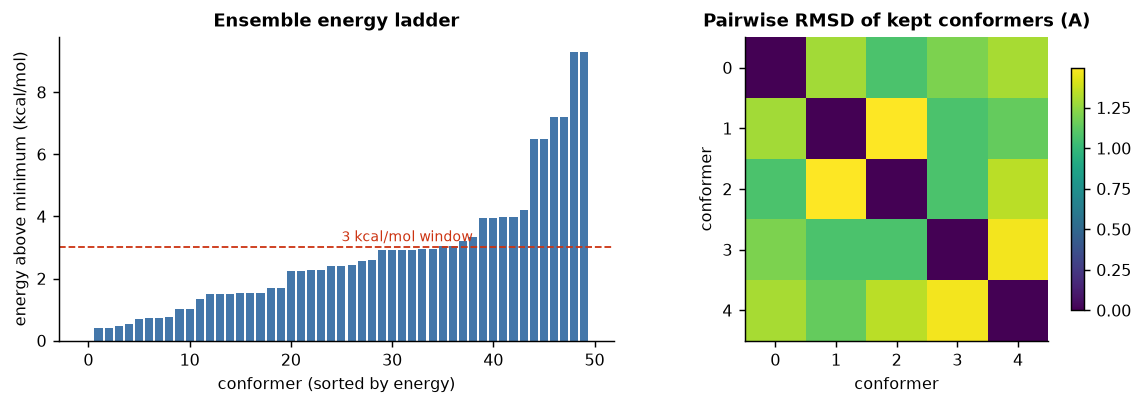

In [8]:
# Prune near-duplicate shapes by heavy-atom RMSD, keeping the lowest-energy member of each cluster.
heavy = Chem.RemoveHs(flex)                                             # RMSD on heavy atoms only
def prune_by_rmsd(mol, order, thresh=1.0):
    kept = []
    for cid in order:                                                  # walk conformers low energy -> high
        if all(rdMolAlign.GetBestRMS(mol, mol, prbId=int(cid), refId=int(k)) > thresh for k in kept):
            kept.append(int(cid))
    return kept
kept = prune_by_rmsd(heavy, order, thresh=1.0)
print("after RMSD pruning (1.0 A): %d distinct conformers remain out of %d" % (len(kept), len(order)))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.0, 3.2), gridspec_kw={"width_ratios": [1.2, 1]})
ax1.bar(range(len(rel)), rel, color="#4477aa"); ax1.axhline(3, color="#cc3311", ls="--", lw=1)
ax1.text(len(rel)*0.5, 3.2, "3 kcal/mol window", color="#cc3311", fontsize=8)
ax1.set_xlabel("conformer (sorted by energy)"); ax1.set_ylabel("energy above minimum (kcal/mol)")
ax1.set_title("Ensemble energy ladder")
M = np.array([[rdMolAlign.GetBestRMS(heavy, heavy, prbId=int(a), refId=int(b)) for b in kept] for a in kept])
im = ax2.imshow(M, cmap="viridis"); ax2.set_title("Pairwise RMSD of kept conformers (A)")
ax2.set_xlabel("conformer"); ax2.set_ylabel("conformer"); fig.colorbar(im, ax=ax2, shrink=0.8)
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> Left: the 50 minimised conformers of fluoxetine sorted by energy, plotted as their energy above the lowest conformer found. The ensemble spans roughly 9 kcal/mol; the majority cluster within the 3 kcal/mol window (dashed line) — the shapes actually accessible at body temperature — while a tail of conformers above the line is strained and rarely occupied. Right: the pairwise heavy-atom RMSD matrix of the conformers that survive 1.0 Å pruning. The diagonal is zero (each conformer against itself) and off-diagonal entries are all above the threshold, confirming the kept set is genuinely diverse — no two are the same shape. Fluoxetine, with six rotatable bonds, collapses to a small handful of distinct low-energy conformers after pruning; a rigid molecule would need far fewer and a floppier one many more.</p>

An energy window is a hard cut-off; the smoother statement is that each conformer is populated in proportion to the Boltzmann factor $e^{-\Delta E/RT}$. The next cell converts the energy ladder into actual populations at body temperature, and then asks whether the two force fields even agree on the ordering.

In [9]:
# Boltzmann populations at body temperature: how the ensemble's probability is shared among conformers.
R, T = 1.987e-3, 310.0                                  # gas constant (kcal/mol/K); body temperature (K)
w = np.exp(-rel / (R * T)); popn = w / w.sum()          # rel = energies above the minimum, already sorted
print("rank | dE (kcal/mol) | population at 310 K")
for k in range(4):
    print("  %2d  |    %6.2f     |    %5.1f %%" % (k, rel[k], 100 * popn[k]))
print("lowest conformer: %.0f%%  |  top 3: %.0f%%  |  all within 3 kcal/mol together: %.1f%%"
      % (100 * popn[0], 100 * popn[:3].sum(), 100 * popn[rel <= 3].sum()))

rank | dE (kcal/mol) | population at 310 K
   0  |      0.00     |     18.1 %
   1  |      0.42     |      9.2 %
   2  |      0.42     |      9.1 %
   3  |      0.48     |      8.3 %
lowest conformer: 18%  |  top 3: 36%  |  all within 3 kcal/mol together: 99.4%


In [10]:
# Do MMFF and UFF agree on which conformers are low-energy? Rank-correlate the two force fields.
from scipy.stats import spearmanr
uff_e = [AllChem.UFFGetMoleculeForceField(flex, confId=int(c)).CalcEnergy() for c in range(flex.GetNumConformers())]
rho = spearmanr(energies, uff_e).statistic
print("Spearman rank correlation of MMFF vs UFF conformer energies: %.2f" % rho)
print("(a high value means the two force fields largely agree on the energy ordering of shapes)")

Spearman rank correlation of MMFF vs UFF conformer energies: 0.90
(a high value means the two force fields largely agree on the energy ordering of shapes)


The population table shows that even for a floppy molecule no single conformer dominates — the lowest holds under a fifth of the population and the top three only about a third — yet essentially the entire population lives within the 3 kcal/mol window, which is exactly why that window is a sensible cut-off: it keeps the shapes that matter and discards the ones thermal motion never visits. The Spearman correlation then confirms that MMFF and UFF, despite their different functional forms, rank the conformers similarly, so the ensemble's conclusions are not an artefact of one force field. These are the quantitative habits (populations, not single structures; cross-checking methods) that separate careful 3-D work from hand-waving.

<div class="box warn"><h4>The force-field minimum is not the bioactive conformation</h4><p>It is tempting to take the single lowest-energy conformer as "the" shape of the molecule. Resist it. A protein routinely binds a conformer several kcal/mol above the ligand's gas-phase minimum, paying that cost with favourable contacts. This is why ligand-based 3-D methods compare <em>ensembles</em>, not single structures, and why more exhaustive low-energy sampling schemes exist for cases where a simple embedding is not thorough enough.<sup class="c"><a href="#r25">[25]</a></sup> The actual bound shape, however, is a question for the <em>protein</em>-based methods of the bioinformatics course (docking, co-crystal structures), not for this one. Generating a good ensemble is necessary but never sufficient to know the bioactive shape.</p></div>

## 5. Flexibility: how many conformers do you need?

The size of a sensible ensemble grows with the molecule's flexibility, measured most simply by the number of <strong>rotatable bonds</strong>. Each rotatable bond adds a torsional degree of freedom; if each torsion has on the order of three preferred values, the number of distinct conformers grows roughly exponentially — the combinatorial explosion that makes exhaustive conformer search hopeless for large flexible molecules and keeps this topic firmly in "sample, do not enumerate" territory. The cell below makes the trend visible on a ladder of molecules from rigid to floppy, and shows why counting rotatable bonds alone is a crude flexibility proxy.<sup class="c"><a href="#r21">[21]</a></sup>

        molecule  rotatable_bonds  distinct_confs_from_60
         benzene                0                       1
         aspirin                2                       2
       ibuprofen                4                      11
 diphenhydramine                6                      25
lisdexamfetamine                8                      56


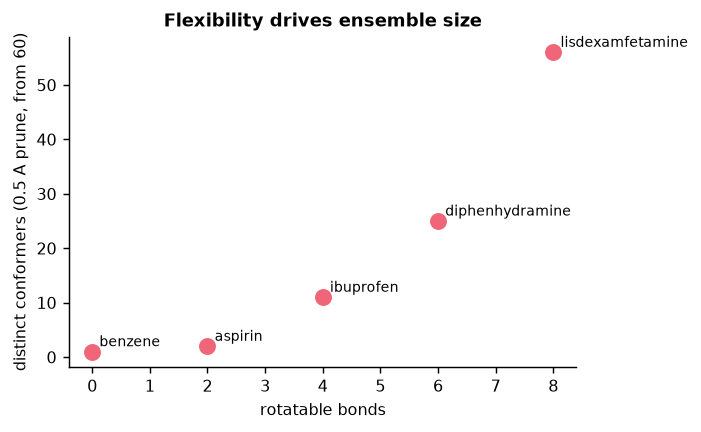

In [11]:
# How conformer diversity scales with flexibility: a rigid-to-floppy ladder of molecules.
ladder = {"benzene": "c1ccccc1", "aspirin": "CC(=O)Oc1ccccc1C(=O)O", "ibuprofen": "CC(C)Cc1ccc(C(C)C(=O)O)cc1",
          "diphenhydramine": "CN(C)CCOC(c1ccccc1)c1ccccc1", "lisdexamfetamine": "CC(Cc1ccccc1)NC(=O)C(N)CCCCN"}
rows = []
for name, smi in ladder.items():
    m = Chem.AddHs(Chem.MolFromSmiles(smi))
    p = AllChem.ETKDGv3(); p.randomSeed = SEED; p.pruneRmsThresh = 0.5     # let RDKit drop near-duplicates
    cids = AllChem.EmbedMultipleConfs(m, numConfs=60, params=p)
    nrot = rdMolDescriptors.CalcNumRotatableBonds(Chem.MolFromSmiles(smi))
    rows.append((name, nrot, len(cids)))
df = pd.DataFrame(rows, columns=["molecule", "rotatable_bonds", "distinct_confs_from_60"]).sort_values("rotatable_bonds")
print(df.to_string(index=False))
fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.scatter(df.rotatable_bonds, df.distinct_confs_from_60, s=70, color="#ee6677", zorder=3)
for _, r in df.iterrows():
    ax.annotate(r.molecule, (r.rotatable_bonds, r.distinct_confs_from_60), fontsize=7.5, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("rotatable bonds"); ax.set_ylabel("distinct conformers (0.5 A prune, from 60)")
ax.set_title("Flexibility drives ensemble size"); fig.tight_layout()

<p class="caption"><b>Figure 4.</b> Distinct conformers surviving a 0.5 Å prune (from 60 embeddings) against the number of rotatable bonds, for molecules from rigid benzene to flexible lisdexamfetamine. More rotatable bonds yield more distinct shapes — the trend is clear and monotone. It is not perfectly linear because rings, symmetry and the 60-conformer sampling cap all intervene: counting rotatable bonds is a cheap flexibility estimate, not an exact one. The practical takeaway is to scale the number of embeddings to the molecule's flexibility — a few dozen for a rigid scaffold, hundreds for a floppy chain — rather than using a fixed number blindly.</p>

Flexibility is not only about <em>how many</em> conformers but about <em>which torsions move</em>. The cell below tracks one rotatable bond of the fluoxetine ensemble and shows that it populates the discrete staggered "rotamer wells" organic chemistry predicts, rather than taking arbitrary angles.

In [12]:
# How a single rotatable bond samples its rotamer wells across the fluoxetine ensemble.
from rdkit.Chem import rdMolTransforms
rotbond = Chem.MolFromSmarts("[!$(*#*)&!D1]-&!@[!$(*#*)&!D1]")
a, b = flex.GetSubstructMatches(rotbond)[0]                 # the first rotatable bond
na = [n.GetIdx() for n in flex.GetAtomWithIdx(a).GetNeighbors() if n.GetIdx() != b][0]
nb = [n.GetIdx() for n in flex.GetAtomWithIdx(b).GetNeighbors() if n.GetIdx() != a][0]
ang = np.array([rdMolTransforms.GetDihedralDeg(flex.GetConformer(int(c)), na, a, b, nb)
                for c in range(flex.GetNumConformers())])
print("torsion around the %s-%s bond across %d conformers: min %.0f, max %.0f deg"
      % (flex.GetAtomWithIdx(a).GetSymbol(), flex.GetAtomWithIdx(b).GetSymbol(), len(ang), ang.min(), ang.max()))
wells = sorted(set(int(round(x / 120.0)) * 120 % 360 for x in ang))
print("approximate rotamer wells occupied (deg, folded to 0-360):", wells)

torsion around the C-N bond across 50 conformers: min -180, max 179 deg
approximate rotamer wells occupied (deg, folded to 0-360): [0, 120, 240]


The torsion does not wander continuously; it clusters around a few values roughly 120° apart — the staggered conformations that minimise steric strain. This is why conformer generation can be framed as choosing a well for each rotatable bond rather than searching a continuous space, and why the number of conformers scales like (wells per bond) raised to the number of rotatable bonds. The discreteness is also what makes RMSD pruning effective: two embeddings that fall into the same set of wells are the same conformer.

## 6. Aligning molecules in 3-D

To compare two shapes you must first put them in a common frame of reference — you cannot compare two objects that float at arbitrary positions and orientations. <strong>Alignment</strong> (superposition) rotates and translates one molecule onto another to maximise overlap. There are two regimes.

When the two things have the <em>same</em> atoms in the same order — for example two conformers of one molecule, or a molecule against itself — the optimal rigid superposition is a classic, closed-form linear-algebra problem. Centre both coordinate sets on their centroids, form a cross-covariance matrix, and read the best rotation from its singular-value decomposition. This is the <strong>Kabsch algorithm</strong>,<sup class="c"><a href="#r11">[11]</a></sup> and it is exactly what RDKit's <code>AlignMol</code> and <code>GetBestRMS</code> use to report the RMSD between conformers (we used it in Section 4). It requires an atom-to-atom correspondence. The cell below runs the four Kabsch steps in NumPy on two fluoxetine conformers and checks the result against RDKit.

In [13]:
# Kabsch alignment by hand (numpy) on two fluoxetine conformers, confirmed against RDKit.
hv = Chem.RemoveHs(flex)
X = hv.GetConformer(0).GetPositions(); Y = hv.GetConformer(1).GetPositions()
Xc = X - X.mean(0); Yc = Y - Y.mean(0)                     # 1) centre both sets on their centroids
Hmat = Xc.T @ Yc                                           # 2) 3x3 cross-covariance matrix
U, S, Vt = np.linalg.svd(Hmat)                             # 3) singular-value decomposition
dsign = np.sign(np.linalg.det(Vt.T @ U.T))                # 4) correct for a possible reflection
Ropt = Vt.T @ np.diag([1, 1, dsign]) @ U.T                #    the optimal rotation matrix
rmsd_hand = np.sqrt(((Yc - Xc @ Ropt.T) ** 2).sum() / len(Xc))
print("Kabsch RMSD by hand (numpy):      %.3f A" % rmsd_hand)
print("RDKit AlignMol (same atom order): %.3f A" % rdMolAlign.AlignMol(Chem.Mol(hv), Chem.Mol(hv), prbCid=0, refCid=1))
print("RDKit GetBestRMS (symmetry-aware): %.3f A" % rdMolAlign.GetBestRMS(hv, hv, prbId=0, refId=1))

Kabsch RMSD by hand (numpy):      1.566 A
RDKit AlignMol (same atom order): 1.566 A
RDKit GetBestRMS (symmetry-aware): 0.590 A


The hand-coded Kabsch RMSD matches RDKit's <code>AlignMol</code> to three decimals, because both use the identical atom correspondence and the same closed-form solution — the SVD <em>is</em> the algorithm, not an approximation to it. RDKit's <code>GetBestRMS</code> returns a slightly smaller value because it additionally searches over symmetry-equivalent atom mappings (for example, the two ortho positions of a phenyl ring are interchangeable), finding a correspondence the naive atom order misses. The lesson for the practitioner: when you compare conformers of symmetric molecules, use the symmetry-aware RMSD, or you will overstate how different two shapes are.

When the two molecules are <em>different</em> — a congeneric series, or a scaffold-hopping pair — there is no obvious atom correspondence, so rigid Kabsch does not apply. Field-based methods align on properties instead. <strong>O3A</strong> (Open3DAlign) superimposes molecules by matching their MMFF atom types and pharmacophoric features, returning an alignment and a score that rewards chemically-similar atoms sitting in the same place.<sup class="c"><a href="#r14">[14]</a></sup> It is the workhorse for overlaying a series of distinct actives. The cell aligns three "profen" anti-inflammatory drugs onto ibuprofen with O3A.

O3A alignment onto ibuprofen (higher score = better chemical+shape overlap):
  naproxen      O3A score  106.8   RMSD-to-ref 0.39 A
  ketoprofen    O3A score   96.8   RMSD-to-ref 0.34 A
  flurbiprofen  O3A score   89.9   RMSD-to-ref 0.44 A


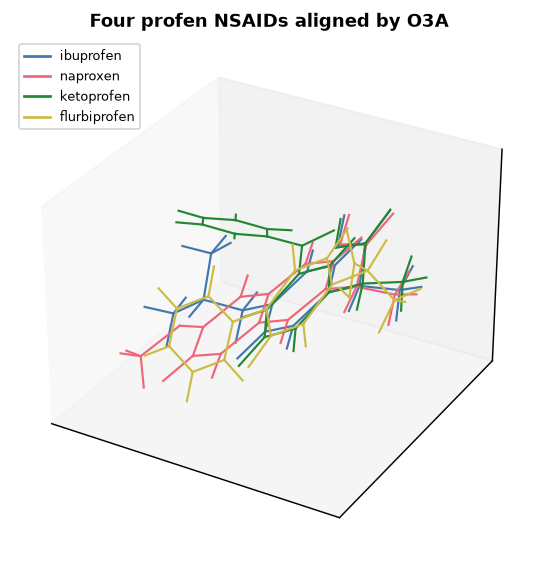

In [14]:
# Align a small congeneric series (profen NSAIDs) onto ibuprofen with O3A, then overlay in 3-D.
def prep(smi):
    m = Chem.AddHs(Chem.MolFromSmiles(smi)); p = AllChem.ETKDGv3(); p.randomSeed = SEED
    AllChem.EmbedMolecule(m, p); AllChem.MMFFOptimizeMolecule(m); return m
series = {"ibuprofen": "CC(C)Cc1ccc(C(C)C(=O)O)cc1", "naproxen": "COc1ccc2cc(C(C)C(=O)O)ccc2c1",
          "ketoprofen": "CC(C(=O)O)c1cccc(C(=O)c2ccccc2)c1", "flurbiprofen": "CC(C(=O)O)c1ccc(-c2ccccc2)c(F)c1"}
mols = {n: prep(s) for n, s in series.items()}
ref = mols["ibuprofen"]; refp = AllChem.MMFFGetMoleculeProperties(ref)
print("O3A alignment onto ibuprofen (higher score = better chemical+shape overlap):")
scores = {}
for n, m in mols.items():
    if n == "ibuprofen": scores[n] = None; continue
    o3a = rdMolAlign.GetO3A(m, ref, AllChem.MMFFGetMoleculeProperties(m), refp)
    scores[n] = round(o3a.Align(), 2)                        # Align() moves m onto ref and returns the RMSD
    print("  %-13s O3A score %6.1f   RMSD-to-ref %.2f A" % (n, o3a.Score(), scores[n]))
fig = plt.figure(figsize=(5.2, 4.4)); ax = fig.add_subplot(projection="3d")
cols = ["#4477aa", "#ee6677", "#228833", "#ccbb44"]
for (n, m), c in zip(mols.items(), cols):
    P = m.GetConformer().GetPositions()
    for b in m.GetBonds():
        i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx(); ax.plot(*zip(P[i], P[j]), color=c, lw=1.2)
ax.set_title("Four profen NSAIDs aligned by O3A"); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
ax.legend(handles=[plt.Line2D([], [], color=c, label=n) for n, c in zip(mols, cols)], fontsize=7, loc="upper left")
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> Four profen anti-inflammatory drugs superimposed by O3A onto ibuprofen (each molecule drawn in one colour). They share a common pharmacophore — an aromatic system bearing a carboxylic-acid "arm" — and O3A places those shared features on top of one another, so the acid groups and aromatic rings coincide while the variable tails splay out. The printed O3A scores rank how well each probe overlays the reference; the sub-ångström RMSDs confirm tight superposition of the common core. This kind of overlay is the visual backbone of ligand-based design: it shows at a glance which parts of a series are conserved and which vary.</p>

<div class="box bridge"><h4>Chemistry box — pharmacophore</h4>
<p>A <strong>pharmacophore</strong> is the arrangement in space of the chemical features responsible for a molecule's activity — for example "a hydrogen-bond donor, a hydrogen-bond acceptor and an aromatic ring at a fixed geometry".<sup class="c"><a href="#r20">[20]</a></sup> It abstracts away the atoms and keeps only the interacting features and their 3-D positions, so two chemically different molecules can share one pharmacophore; three-dimensional pharmacophore methods are a mature branch of ligand-based design.<sup class="c"><a href="#r19">[19]</a></sup> Aligning on pharmacophoric features (as O3A does) is how ligand-based methods recognise that a new scaffold can play the same biological role as a known drug — the basis of "scaffold hopping".<sup class="c"><a href="#r8">[8]</a></sup></p></div>

## 7. Shape similarity

Once two molecules are aligned, we can ask how much of their volume overlaps. The standard formalism represents each atom as a soft Gaussian sphere, so the whole molecule becomes a smooth density in space; the overlap of two such densities is a fast, differentiable measure of shape match.<sup class="c"><a href="#r7">[7]</a></sup> Normalising the overlap gives a <strong>shape Tanimoto</strong> that reuses exactly the Tanimoto coefficient you met for fingerprints in Unit 5 — only now the "features" are volume elements rather than bits:

<div class="eq">$$T_{\text{shape}} = \frac{O_{AB}}{O_{AA} + O_{BB} - O_{AB}}$$
<span class="where">where $O_{AB}$ is the overlap volume of molecules $A$ and $B$ and $O_{AA}$, $O_{BB}$ are their self-overlaps. $T_{\text{shape}} = 1$ means identical shape, $0$ means no overlap. RDKit reports the <em>distance</em> $1 - T$, so similarity is one minus the returned value.</span></div>

Shape similarity is the engine of shape-based virtual screening: tools such as ROCS rank a library by 3-D similarity to a query and recover actives that 2-D fingerprints miss, because shape is agnostic to the exact atoms.<sup class="c"><a href="#r9">[9]</a></sup> It is a genuinely ligand-only method — no protein required — which is why it belongs in this unit. The cell computes shape Tanimoto for the profen series after O3A alignment, and also the <em>protrude</em> distance, which measures how much of the smaller molecule sticks out of the larger.

    molecule  shape_Tanimoto_to_ibuprofen  protrude_dist
    naproxen                        0.668          0.176
  ketoprofen                        0.530          0.244
flurbiprofen                        0.601          0.205


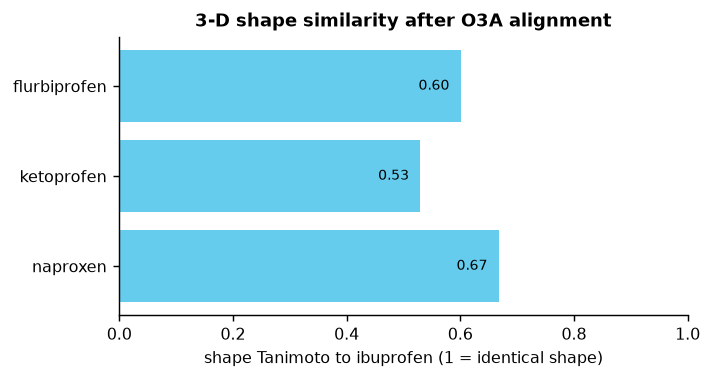

In [15]:
# Shape Tanimoto and protrude distance between each profen and ibuprofen, measured AFTER O3A alignment.
rows = []
for n, m in mols.items():
    if n == "ibuprofen": continue
    o3a = rdMolAlign.GetO3A(m, ref, AllChem.MMFFGetMoleculeProperties(m), refp); o3a.Align()  # align first!
    shape_sim = 1.0 - rdShapeHelpers.ShapeTanimotoDist(m, ref)     # similarity = 1 - distance
    protrude = rdShapeHelpers.ShapeProtrudeDist(m, ref)            # fraction of volume protruding
    rows.append((n, round(shape_sim, 3), round(protrude, 3)))
sh = pd.DataFrame(rows, columns=["molecule", "shape_Tanimoto_to_ibuprofen", "protrude_dist"])
print(sh.to_string(index=False))
fig, ax = plt.subplots(figsize=(5.6, 3.0))
ax.barh(sh.molecule, sh.shape_Tanimoto_to_ibuprofen, color="#66ccee")
for y, v in enumerate(sh.shape_Tanimoto_to_ibuprofen):
    ax.text(v - 0.02, y, f"{v:.2f}", va="center", ha="right", fontsize=8, color="k")
ax.set_xlim(0, 1); ax.set_xlabel("shape Tanimoto to ibuprofen (1 = identical shape)")
ax.set_title("3-D shape similarity after O3A alignment"); fig.tight_layout()

<p class="caption"><b>Figure 6.</b> Shape Tanimoto of three profens to ibuprofen after O3A alignment. All three score moderately to highly (roughly 0.5–0.7) — these drugs are built around the same compact aromatic-plus-acid core, so their volumes overlap well once superimposed. Ketoprofen scores lowest and protrudes most (its pendant benzoyl group adds bulk that falls outside ibuprofen's volume), while naproxen's fused ring packs more compactly against the reference, as the protrude column shows. A key caveat: shape similarity is only as meaningful as the alignment it rests on — a poor superposition produces a low shape score for molecules that are in fact similar, so shape methods live or die by their alignment step. That dependence motivates the <em>alignment-free</em> shape descriptors we meet in Section 9.</p>

## 8. 3-D descriptors and the shape triangle

Shape similarity compares two molecules; a <strong>3-D descriptor</strong> instead summarises one molecule's shape as a number (or a short vector), so it can be plotted, clustered or fed to a model exactly like the 2-D descriptors of Unit 12. The most interpretable family comes from the <strong>principal moments of inertia</strong> (PMI). Treat each atom as a point mass at its coordinates; the moment-of-inertia tensor measures how that mass is distributed about the centre, and its three eigenvalues $I_1 \le I_2 \le I_3$ are the principal moments — the mass spread about the three principal axes. Their ratios are dimensionless shape coordinates:

<div class="eq">$$\text{NPR1} = \frac{I_1}{I_3}, \qquad \text{NPR2} = \frac{I_2}{I_3}$$
<span class="where">Normalising by the largest moment removes size, leaving pure shape. Plotting NPR2 against NPR1 places every molecule inside a triangle whose corners are the three extreme shapes: a <strong>rod</strong> (linear) at (0, 1), a <strong>disc</strong> (flat) at (0.5, 0.5), and a <strong>sphere</strong> (globular) at (1, 1).<sup class="c"><a href="#r10">[10]</a></sup></span></div>

### 8.1 Worked example by hand: principal moments from coordinates

The algorithm is pure linear algebra, so we can trace it on paper. Take three equal point masses at $(0,0,0)$, $(2,0,0)$ and $(0,2,0)$ — a right-isosceles triangle in the $xy$-plane.

<strong>Step 1 — centre of mass.</strong> With equal masses it is the mean of the coordinates: $\bar{\mathbf{r}} = (\tfrac{2}{3}, \tfrac{2}{3}, 0)$. Shift every point by $-\bar{\mathbf{r}}$: $p_1=(-\tfrac23,-\tfrac23,0)$, $p_2=(\tfrac43,-\tfrac23,0)$, $p_3=(-\tfrac23,\tfrac43,0)$.

<strong>Step 2 — inertia tensor.</strong> Using $I_{xx}=\sum m(y^2+z^2)$, $I_{yy}=\sum m(x^2+z^2)$, $I_{zz}=\sum m(x^2+y^2)$ and $I_{xy}=-\sum m\,xy$ (with $z=0$ everywhere):
$$I_{xx}=\tfrac{4}{9}+\tfrac{4}{9}+\tfrac{16}{9}=\tfrac{8}{3},\quad I_{yy}=\tfrac{8}{3},\quad I_{zz}=\tfrac{48}{9}=\tfrac{16}{3},\quad I_{xy}=-\!\left(\tfrac{4}{9}-\tfrac{8}{9}-\tfrac{8}{9}\right)=\tfrac{4}{3}.$$

<strong>Step 3 — eigenvalues.</strong> The tensor is block-diagonal; the $2\times2$ block $\big[\begin{smallmatrix}8/3 & 4/3\\ 4/3 & 8/3\end{smallmatrix}\big]$ has eigenvalues $\tfrac83\pm\tfrac43 = \{\tfrac43,\,4\}$, and the third eigenvalue is $I_{zz}=\tfrac{16}{3}$. Sorted: $I_1=\tfrac43\approx1.333$, $I_2=4$, $I_3=\tfrac{16}{3}\approx5.333$.

<strong>Step 4 — shape coordinates.</strong> $\text{NPR1}=\tfrac{4/3}{16/3}=0.25$, $\text{NPR2}=\tfrac{4}{16/3}=0.75$. Note $\text{NPR1}+\text{NPR2}=1$: a flat object satisfies $I_3=I_1+I_2$ (the perpendicular-axis theorem), so every planar molecule lies on the rod–disc edge of the triangle. The cell confirms the arithmetic with NumPy and shows RDKit computes the same NPRs (with real atomic masses) for molecules of each archetypal shape.

In [16]:
# Confirm the hand-traced PMI/NPR by hand, by numpy, and against RDKit on archetypal shapes.
pts = np.array([[0, 0, 0], [2, 0, 0], [0, 2, 0]], float); mass = np.ones(3)
com = (pts * mass[:, None]).sum(0) / mass.sum(); q = pts - com          # step 1: centre
I = np.zeros((3, 3))                                                    # step 2: inertia tensor
for mi, (x, y, z) in zip(mass, q):
    I += mi * np.array([[y*y+z*z, -x*y, -x*z], [-x*y, x*x+z*z, -y*z], [-x*z, -y*z, x*x+y*y]])
ev = np.sort(np.linalg.eigvalsh(I))                                     # step 3: eigenvalues
print("hand result  I =", [float(round(v, 3)) for v in ev], "-> NPR1 %.3f  NPR2 %.3f" % (ev[0]/ev[2], ev[1]/ev[2]))
print("expected     I = [1.333, 4.0, 5.333] -> NPR1 0.250  NPR2 0.750  (match)")
archetypes = {"dodecane (rod)": "CCCCCCCCCCCC", "benzene (disc)": "c1ccccc1", "adamantane (sphere)": "C1C2CC3CC1CC(C2)C3"}
for n, s in archetypes.items():
    m = Chem.AddHs(Chem.MolFromSmiles(s)); p = AllChem.ETKDGv3(); p.randomSeed = SEED
    AllChem.EmbedMolecule(m, p); AllChem.MMFFOptimizeMolecule(m)
    print("  %-20s RDKit NPR1 %.3f  NPR2 %.3f" % (n, rdMolDescriptors.CalcNPR1(m), rdMolDescriptors.CalcNPR2(m)))

hand result  I = [1.333, 4.0, 5.333] -> NPR1 0.250  NPR2 0.750
expected     I = [1.333, 4.0, 5.333] -> NPR1 0.250  NPR2 0.750  (match)
  dodecane (rod)       RDKit NPR1 0.045  NPR2 0.977
  benzene (disc)       RDKit NPR1 0.500  NPR2 0.500
  adamantane (sphere)  RDKit NPR1 1.000  NPR2 1.000


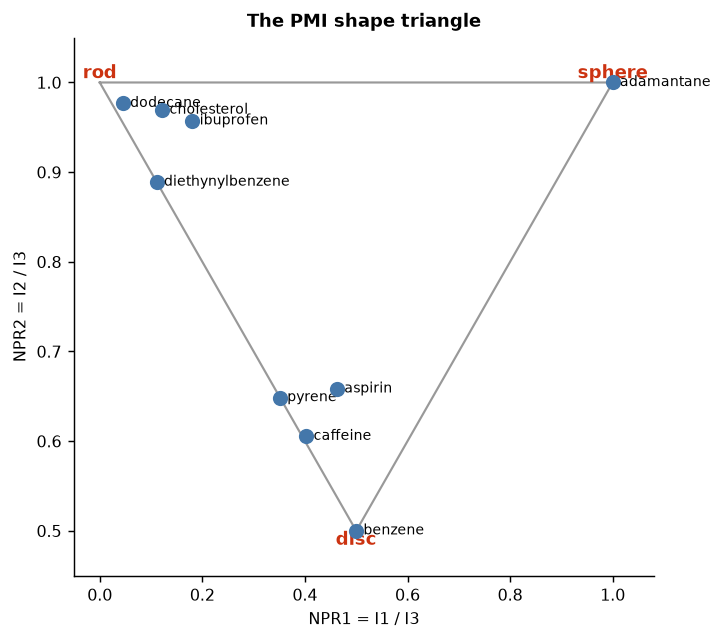

In [17]:
# The shape triangle: place real drugs and archetypes by their (NPR1, NPR2) shape coordinates.
zoo = {"dodecane": "CCCCCCCCCCCC", "diethynylbenzene": "C#Cc1ccc(C#C)cc1", "ibuprofen": "CC(C)Cc1ccc(C(C)C(=O)O)cc1",
       "benzene": "c1ccccc1", "pyrene": "c1cc2ccc3cccc4ccc(c1)c2c34", "aspirin": "CC(=O)Oc1ccccc1C(=O)O",
       "caffeine": "Cn1cnc2c1c(=O)n(C)c(=O)n2C", "adamantane": "C1C2CC3CC1CC(C2)C3",
       "cholesterol": "CC(C)CCCC(C)C1CCC2C1(C)CCC1C2CC=C2CC(O)CCC12C"}
pts = {}
for n, s in zoo.items():
    m = Chem.AddHs(Chem.MolFromSmiles(s)); p = AllChem.ETKDGv3(); p.randomSeed = SEED
    AllChem.EmbedMolecule(m, p); AllChem.MMFFOptimizeMolecule(m)
    pts[n] = (rdMolDescriptors.CalcNPR1(m), rdMolDescriptors.CalcNPR2(m))
fig, ax = plt.subplots(figsize=(5.6, 5.0))
ax.plot([0, 0.5, 1, 0], [1, 0.5, 1, 1], color="#999999", lw=1.2)        # the rod-disc-sphere triangle
for lbl, xy in [("rod", (0, 1)), ("disc", (0.5, 0.5)), ("sphere", (1, 1))]:
    ax.annotate(lbl, xy, fontsize=10, fontweight="bold", color="#cc3311",
                ha="center", va="bottom" if lbl != "disc" else "top")
for n, (a, b) in pts.items():
    ax.scatter(a, b, s=55, color="#4477aa", zorder=3)
    ax.annotate(n, (a, b), fontsize=7.5, xytext=(4, -2), textcoords="offset points")
ax.set_xlabel("NPR1 = I1 / I3"); ax.set_ylabel("NPR2 = I2 / I3")
ax.set_xlim(-0.05, 1.08); ax.set_ylim(0.45, 1.05); ax.set_title("The PMI shape triangle")
fig.tight_layout()

<p class="caption"><b>Figure 7.</b> The principal-moments-of-inertia shape triangle. Every molecule's normalised shape sits inside the triangle whose corners are the three extreme shapes. Linear molecules (dodecane, diethynylbenzene) hug the rod corner; flat aromatics (benzene, pyrene, and the mostly-planar aspirin and caffeine) lie along the bottom rod–disc edge, exactly as the hand-traced perpendicular-axis result predicts for planar objects; the cage-like adamantane sits at the sphere corner, and the fused-ring steroid cholesterol and the branched ibuprofen fall in the interior. This single plot captures the "escape from flatland" idea quantitatively — medicinal chemists increasingly prize three-dimensional (interior and sphere-ward) molecules over flat ones,<sup class="c"><a href="#r12">[12]</a></sup> and the triangle is the standard way to visualise the shape diversity of a whole library at a glance.</p>

<div class="box key"><h4>Other useful 3-D descriptors</h4>
<p>Beyond the NPR pair, RDKit computes several single-number 3-D shape descriptors you will meet in QSAR feature sets: the <strong>radius of gyration</strong> (overall size/extension), <strong>asphericity</strong> (0 for a sphere, 1 for a rod), the <strong>spherocity index</strong>, the <strong>plane-of-best-fit</strong> (PBF, the mean atom distance from the best-fitting plane — a direct flatness measure),<sup class="c"><a href="#r13">[13]</a></sup> and the cheap 2-D proxy <strong>Fsp3</strong> (the fraction of carbons that are sp3, which correlates with three-dimensionality without needing coordinates at all). The next cell tabulates them.</p></div>

In [18]:
# A panel of 3-D shape descriptors (plus the coordinate-free Fsp3 proxy) for the same molecule zoo.
rows = []
for n, s in zoo.items():
    m = Chem.AddHs(Chem.MolFromSmiles(s)); p = AllChem.ETKDGv3(); p.randomSeed = SEED
    AllChem.EmbedMolecule(m, p); AllChem.MMFFOptimizeMolecule(m)
    rows.append((n, round(rdMolDescriptors.CalcRadiusOfGyration(m), 2), round(rdMolDescriptors.CalcAsphericity(m), 3),
                 round(rdMolDescriptors.CalcSpherocityIndex(m), 3), round(rdMolDescriptors.CalcPBF(m), 3),
                 round(Descriptors.FractionCSP3(Chem.MolFromSmiles(s)), 3)))
d3 = pd.DataFrame(rows, columns=["molecule", "radius_gyration", "asphericity", "spherocity", "PBF_flatness", "Fsp3"])
print(d3.to_string(index=False))
print("\nFlatness check: PBF is near 0 for planar aromatics and larger for 3-D cages:")
print("  benzene PBF %.3f  vs  adamantane PBF %.3f" % (d3.set_index('molecule').loc['benzene','PBF_flatness'],
                                                       d3.set_index('molecule').loc['adamantane','PBF_flatness']))

        molecule  radius_gyration  asphericity  spherocity  PBF_flatness  Fsp3
        dodecane             4.08        0.871       0.093         0.581 1.000
diethynylbenzene             2.52        0.704       0.000         0.000 0.000
       ibuprofen             3.28        0.558       0.263         0.894 0.462
         benzene             1.51        0.250       0.000         0.000 0.000
          pyrene             2.63        0.316       0.000         0.000 0.000
         aspirin             2.43        0.197       0.097         0.383 0.111
        caffeine             2.46        0.274       0.067         0.224 0.375
      adamantane             1.82        0.000       1.000         1.118 1.000
     cholesterol             4.82        0.681       0.197         1.096 0.926

Flatness check: PBF is near 0 for planar aromatics and larger for 3-D cages:
  benzene PBF 0.000  vs  adamantane PBF 1.118


The table reads as a shape fingerprint for each molecule. Asphericity rises from the near-spherical adamantane towards the rod-like alkane; the plane-of-best-fit distance is tiny for the flat aromatics (benzene, pyrene) and substantial for the three-dimensional cage and steroid; radius of gyration tracks overall size. Fsp3 — computable from the graph alone, with no embedding — is low for the aromatic-heavy molecules and high for the saturated adamantane and cholesterol, which is why it is a popular cheap stand-in for "three-dimensionality" in drug-likeness filters. Each of these is one column you could add to a QSAR model (Unit 12) when activity depends on shape, not just composition.

## 9. 3-D shape versus 2-D fingerprint similarity

Why bother with 3-D at all, when the 2-D fingerprints of Unit 5 are faster and need no conformers? Because the two measures answer different questions. A 2-D Tanimoto asks "do these molecules share substructures / connectivity?"; a 3-D shape Tanimoto asks "do these molecules occupy space the same way?". Usually they agree, but they diverge in the case that matters most for discovery: <strong>scaffold hopping</strong> — finding a molecule with a <em>different</em> chemical skeleton (low 2-D similarity) but the <em>same</em> shape and feature layout (high 3-D similarity), which can therefore hit the same target while escaping a patent or a toxicity liability.<sup class="c"><a href="#r9">[9]</a></sup> The cell computes both similarities from a shared query over a small mixed set and plots one against the other.

            molecule  Tanimoto_2D  shape_3D
            naproxen        0.421     0.668
          ketoprofen        0.395     0.530
          diclofenac        0.167     0.332
             aspirin        0.195     0.382
            caffeine        0.087     0.425
         paracetamol        0.184     0.504
biphenyl-acetic acid        0.278     0.655


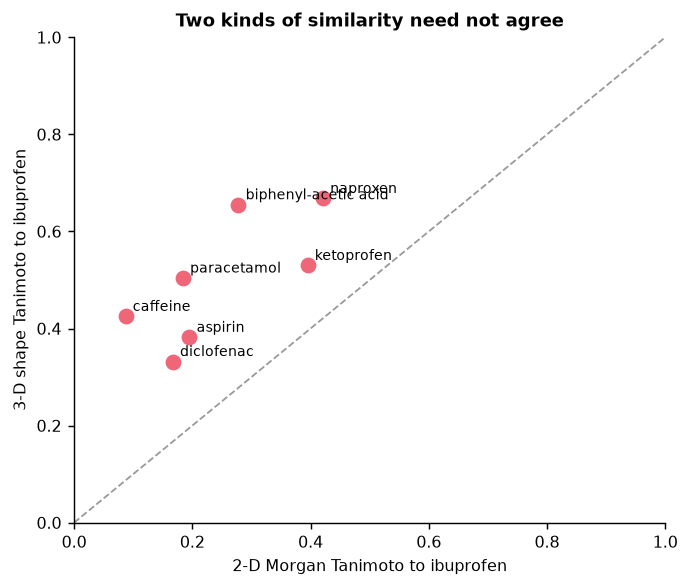

In [19]:
# 2-D (Morgan/ECFP) Tanimoto vs 3-D (O3A-aligned shape) Tanimoto, both measured to a common query: ibuprofen.
from rdkit.Chem import rdFingerprintGenerator, DataStructs
testset = {"naproxen": "COc1ccc2cc(C(C)C(=O)O)ccc2c1", "ketoprofen": "CC(C(=O)O)c1cccc(C(=O)c2ccccc2)c1",
           "diclofenac": "OC(=O)Cc1ccccc1Nc1c(Cl)cccc1Cl", "aspirin": "CC(=O)Oc1ccccc1C(=O)O",
           "caffeine": "Cn1cnc2c1c(=O)n(C)c(=O)n2C", "paracetamol": "CC(=O)Nc1ccc(O)cc1",
           "biphenyl-acetic acid": "OC(=O)Cc1ccc(-c2ccccc2)cc1"}
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
query = Chem.MolFromSmiles("CC(C)Cc1ccc(C(C)C(=O)O)cc1"); qfp = gen.GetFingerprint(query)
q3d = prep("CC(C)Cc1ccc(C(C)C(=O)O)cc1"); q3dp = AllChem.MMFFGetMoleculeProperties(q3d)
rows = []
for n, s in testset.items():
    sim2d = DataStructs.TanimotoSimilarity(qfp, gen.GetFingerprint(Chem.MolFromSmiles(s)))
    m = prep(s); rdMolAlign.GetO3A(m, q3d, AllChem.MMFFGetMoleculeProperties(m), q3dp).Align()
    sim3d = 1.0 - rdShapeHelpers.ShapeTanimotoDist(m, q3d)
    rows.append((n, round(sim2d, 3), round(sim3d, 3)))
cmp = pd.DataFrame(rows, columns=["molecule", "Tanimoto_2D", "shape_3D"])
print(cmp.to_string(index=False))
fig, ax = plt.subplots(figsize=(5.4, 4.6))
ax.scatter(cmp.Tanimoto_2D, cmp.shape_3D, s=60, color="#ee6677", zorder=3)
for _, r in cmp.iterrows():
    ax.annotate(r.molecule, (r.Tanimoto_2D, r.shape_3D), fontsize=7.5, xytext=(4, 3), textcoords="offset points")
ax.plot([0, 1], [0, 1], "--", color="#999999", lw=1); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("2-D Morgan Tanimoto to ibuprofen"); ax.set_ylabel("3-D shape Tanimoto to ibuprofen")
ax.set_title("Two kinds of similarity need not agree"); fig.tight_layout()

<p class="caption"><b>Figure 8.</b> Each molecule's 2-D fingerprint similarity to ibuprofen (horizontal) against its 3-D shape similarity (vertical); the dashed line is equality. Every point lies above the line — shape similarity exceeds fingerprint similarity for the whole set — but the gap is the interesting quantity: it is largest for molecules whose connectivity differs sharply from ibuprofen (low 2-D Tanimoto) yet whose overall shape still matches (higher 3-D shape Tanimoto). Biphenyl-acetic acid is the clearest case — a different skeleton (2-D ≈ 0.28) with a markedly more similar compact aromatic-acid shape (3-D ≈ 0.66) — and paracetamol and caffeine show the same divergence from much lower 2-D starting points. A 2-D-only screen would rank these low and miss them; a shape screen recovers them. This is precisely the regime where adding the third dimension earns its cost. Conversely, when 2-D and 3-D agree, the cheaper 2-D method is the rational choice — depth is a tool, not a default.</p>

## 10. Alignment-free shape: USR and pharmacophoric shape

Every shape comparison so far required an alignment, which is both slow and fragile. An alternative skips alignment entirely by describing each conformer with rotation- and translation-invariant statistics. <strong>USR</strong> (Ultrafast Shape Recognition) measures the distribution of atom distances from four reference points (the molecular centroid and the atoms closest to, farthest from, and farthest from that farthest atom) and summarises each distribution by its first three moments — a 12-number vector per conformer.<sup class="c"><a href="#r17">[17]</a></sup> Because the moments are geometry-invariant, two USR vectors can be compared directly, with no superposition, at the speed of a dot product — fast enough to screen millions of molecules. <strong>USRCAT</strong> extends the idea by computing the same moments separately for pharmacophoric atom subsets (hydrophobic, aromatic, donor, acceptor), so it rewards shape <em>and</em> feature match in a 60-number vector.<sup class="c"><a href="#r18">[18]</a></sup> A related alignment-free idea extends extended-connectivity fingerprints into 3-D (E3FP).<sup class="c"><a href="#r22">[22]</a></sup>

            molecule  USR_score  USRCAT_score
biphenyl-acetic acid      0.877         0.199
          ketoprofen      0.786         0.184
          diclofenac      0.738         0.170
            naproxen      0.732         0.200
         paracetamol      0.700         0.193
             aspirin      0.619         0.204
            caffeine      0.608         0.131


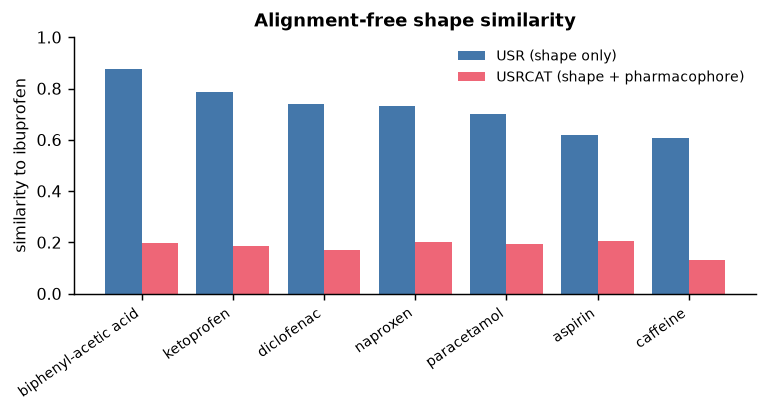

In [20]:
# USR and USRCAT: alignment-free shape similarity of the test set to ibuprofen (no superposition needed).
qu = rdMolDescriptors.GetUSR(q3d); qc = rdMolDescriptors.GetUSRCAT(q3d)
rows = []
for n, s in testset.items():
    m = prep(s)
    usr = rdMolDescriptors.GetUSRScore(rdMolDescriptors.GetUSR(m), qu)        # 1 = identical shape
    cat = rdMolDescriptors.GetUSRScore(rdMolDescriptors.GetUSRCAT(m), qc)     # shape + pharmacophore
    rows.append((n, round(usr, 3), round(cat, 3)))
u = pd.DataFrame(rows, columns=["molecule", "USR_score", "USRCAT_score"]).sort_values("USR_score", ascending=False)
print(u.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.0, 3.2)); x = np.arange(len(u))
ax.bar(x - 0.2, u.USR_score, 0.4, label="USR (shape only)", color="#4477aa")
ax.bar(x + 0.2, u.USRCAT_score, 0.4, label="USRCAT (shape + pharmacophore)", color="#ee6677")
ax.set_xticks(x); ax.set_xticklabels(u.molecule, rotation=35, ha="right", fontsize=7.5)
ax.set_ylabel("similarity to ibuprofen"); ax.set_ylim(0, 1); ax.legend(fontsize=7.5, frameon=False)
ax.set_title("Alignment-free shape similarity"); fig.tight_layout()

<p class="caption"><b>Figure 9.</b> Alignment-free similarity of each test molecule to ibuprofen: USR (shape only) beside USRCAT (shape plus pharmacophoric features). USR alone, judging shape with no chemistry, can rate a molecule of the right size and extension highly even when its chemical features differ; USRCAT usually lowers those scores because it also demands that hydrophobic, aromatic, donor and acceptor atoms sit in the right places. The ranking is computed without a single alignment, which is why USR-family methods are the first-pass filter in billion-molecule shape screens, with slower alignment-based shape (Section 7) reserved for re-scoring the top hits. This mirrors the general cheminformatics pattern of a cheap filter feeding an expensive confirm.</p>

## 11. The ligand-based 3-D pipeline, and where it stops

The methods in this unit chain into a single pipeline that takes a flat SMILES string and ends at a shape comparison or a 3-D descriptor — all without ever touching a protein. The diagram below (drawn by the next cell) lays out that chain and marks explicitly where the ligand-based course stops and the structure-based bioinformatics course begins.

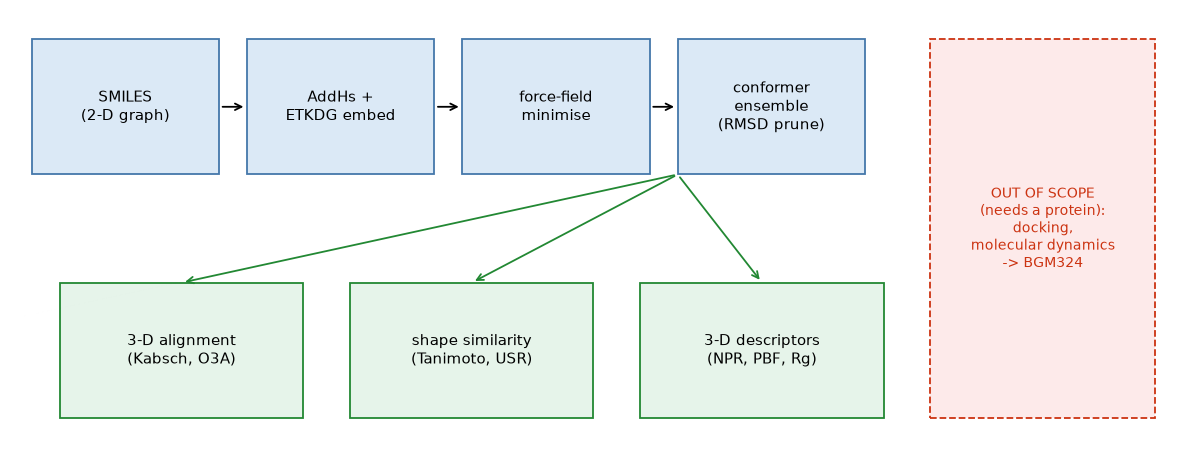

In [21]:
# A schematic of the ligand-based 3-D pipeline and the explicit scope boundary (conceptual diagram).
fig, ax = plt.subplots(figsize=(9.2, 3.6)); ax.axis("off")
steps = ["SMILES\n(2-D graph)", "AddHs +\nETKDG embed", "force-field\nminimise", "conformer\nensemble\n(RMSD prune)"]
for i, t in enumerate(steps):
    ax.add_patch(plt.Rectangle((i*2.3, 2.0), 2.0, 1.0, fc="#dbe9f6", ec="#4477aa"))
    ax.text(i*2.3 + 1.0, 2.5, t, ha="center", va="center", fontsize=8.5)
    if i < len(steps)-1: ax.annotate("", (i*2.3+2.3, 2.5), (i*2.3+2.0, 2.5), arrowprops=dict(arrowstyle="->"))
outs = ["3-D alignment\n(Kabsch, O3A)", "shape similarity\n(Tanimoto, USR)", "3-D descriptors\n(NPR, PBF, Rg)"]
for j, t in enumerate(outs):
    ax.add_patch(plt.Rectangle((j*3.1 + 0.3, 0.2), 2.6, 1.0, fc="#e6f4ea", ec="#228833"))
    ax.text(j*3.1 + 1.6, 0.7, t, ha="center", va="center", fontsize=8.5)
    ax.annotate("", (j*3.1 + 1.6, 1.2), (6.9, 2.0), arrowprops=dict(arrowstyle="->", color="#228833"))
ax.add_patch(plt.Rectangle((9.6, 0.2), 2.4, 2.8, fc="#fdeaea", ec="#cc3311", ls="--"))
ax.text(10.8, 1.6, "OUT OF SCOPE\n(needs a protein):\ndocking,\nmolecular dynamics\n-> BGM324", ha="center",
        va="center", fontsize=8, color="#cc3311")
ax.set_xlim(-0.2, 12.2); ax.set_ylim(0, 3.2)
fig.tight_layout()

<p class="caption"><b>Figure 10.</b> The ligand-based 3-D pipeline. Blue boxes are the generation steps (string → coordinates → relaxed geometry → pruned ensemble); green boxes are the three analyses this unit covers (alignment, shape similarity, 3-D descriptors). The red dashed box is the hard scope boundary: the moment a method needs the <em>protein's</em> 3-D structure — docking a ligand into a binding pocket, or simulating the complex with molecular dynamics — it leaves this course for the structure-based bioinformatics course (BGM324). Everything we did used the small molecule and nothing else.</p>

<div class="box warn"><h4>Three honest limitations of ligand-based 3-D</h4>
<p><strong>(1) The ensemble may miss the bioactive conformer.</strong> A force field ranks conformers by gas-phase energy; the shape a protein selects can be several kcal/mol higher and occasionally absent from a small ensemble. <strong>(2) Everything depends on the alignment or the invariants.</strong> Alignment-based shape scores inherit every alignment error; alignment-free scores (USR) trade that for a coarser description. <strong>(3) 3-D is not automatically better.</strong> On many benchmarks a well-built 2-D fingerprint model matches or beats a 3-D one at a fraction of the cost, because conformer noise can swamp the extra signal. Use 3-D when the biology is demonstrably shape-driven (scaffold hopping, rigid actives), not reflexively.</p></div>

## 12. Summary

You should now be able to explain, without notes:

- Why the 2-D molecular graph cannot express shape, and why a flexible molecule is an <em>ensemble</em> of conformers rather than one structure — one point per rotatable bond in torsion-angle space.
- How distance geometry turns connectivity into coordinates, what ETKDG adds (crystal-derived torsion preferences), and why you must add explicit hydrogens before embedding.
- What a force field is (a fast classical energy = bonded + non-bonded terms, i.e. a hand-crafted differentiable loss over coordinates), the difference between MMFF94 and UFF, and that minimisation finds only a <em>local</em> minimum.
- How to build a conformer ensemble, rank it by energy, apply an energy window, and prune redundant shapes by RMSD — and why the lowest-energy conformer is not the bioactive one.
- How flexibility (rotatable bonds) drives ensemble size, and why conformer space is sampled, not enumerated.
- The two alignment regimes: closed-form Kabsch superposition for identical topologies (RMSD between conformers) and feature-based O3A for different molecules.
- Shape similarity as a Gaussian-volume overlap normalised into a Tanimoto, its dependence on alignment, and the alignment-free USR/USRCAT alternative.
- The PMI shape triangle and the common 3-D descriptors (NPR, radius of gyration, asphericity, plane-of-best-fit, and the cheap Fsp3 proxy), traced by hand from the inertia tensor.
- When 3-D similarity beats 2-D fingerprints (scaffold hopping, shape-driven activity) and when it does not — and that docking and molecular dynamics, which need the protein, are out of scope here and belong to the bioinformatics course.

## 13. Self-assessment

<details><summary>1. What is the difference between a conformation and a configuration, and which one is this unit about?</summary>A <em>conformation</em> (conformer) is a 3-D shape reachable by rotating single bonds only — no bonds broken. A <em>configuration</em> requires breaking and remaking bonds to interconvert (e.g. stereochemistry, Unit 3). This unit is entirely about conformations: generating, ranking and comparing the shapes one molecule can adopt.</details>

<details><summary>2. Why must you call <code>Chem.AddHs</code> before embedding a molecule in 3-D?</summary>Hydrogens occupy space and define the local geometry around each heavy atom. Embedding the heavy-atom-only graph produces distorted bond angles and unrealistic shapes, and downstream 3-D descriptors and energies are then wrong. Add explicit H first, embed, minimise, and optionally remove H for display.</details>

<details><summary>3. What does ETKDG add on top of plain distance geometry, and why does it help?</summary>ETKDG biases the random distance-matrix sampling toward torsion angles observed in experimental crystal structures. Plain distance geometry gives geometrically valid but often chemically implausible torsions and ring puckers; the torsion knowledge nudges embeddings toward conformations chemists actually see, improving quality at almost no cost.</details>

<details><summary>4. A force field reports an MMFF energy of 25 kcal/mol for one conformer and a UFF energy of 60 kcal/mol for another. Which conformer is lower in energy?</summary>You cannot tell: MMFF and UFF energies are on different, incomparable scales (different functional forms and parameters). Only energies from the <em>same</em> force field may be compared. To rank the two conformers, score both with one force field.</details>

<details><summary>5. Why does generating a single conformer and minimising it not give "the" shape of a flexible molecule?</summary>Minimisation rolls downhill to the nearest local minimum, which depends on the random starting geometry. A flexible molecule has many minima; one embed+minimise reaches only one. You must generate many conformers from different starts to sample the accessible shapes.</details>

<details><summary>6. You generate 50 conformers and find 40 are within 3 kcal/mol of the lowest but only 8 survive a 1 Å RMSD prune. What do these two numbers mean?</summary>The energy window (40 within 3 kcal/mol) says most generated conformers are thermally accessible. The RMSD prune (8 remain) says many of those are near-duplicate shapes; only 8 are geometrically distinct. The useful ensemble is the pruned, low-energy set — diverse <em>and</em> populated.</details>

<details><summary>7. Why can you use the Kabsch algorithm to align two conformers of aspirin but not to align aspirin onto ibuprofen?</summary>Kabsch needs an atom-to-atom correspondence; two conformers of the same molecule have identical atoms in the same order, so the mapping is trivial. Aspirin and ibuprofen have different atoms and no natural one-to-one mapping, so you need a feature-based method such as O3A that matches atom types and pharmacophoric features instead.</details>

<details><summary>8. Shape Tanimoto between two similar molecules comes out low. Give a reason that is not "the molecules are dissimilar".</summary>Shape Tanimoto is computed on the current (unaligned or badly aligned) poses; it does not align the molecules itself. A poor superposition yields a low overlap even for genuinely similar shapes. Always align first (e.g. with O3A), or use an alignment-free method (USR).</details>

<details><summary>9. On the PMI shape triangle, where do flat aromatic molecules fall, and why?</summary>Along the bottom rod–disc edge, where NPR1 + NPR2 = 1. For a planar object the perpendicular-axis theorem gives I3 = I1 + I2, so NPR1 + NPR2 = (I1 + I2)/I3 = 1. Benzene sits near the disc corner (0.5, 0.5); a long flat molecule slides toward the rod corner.</details>

<details><summary>10. Hand-compute NPR1 and NPR2 for three equal masses at (0,0,0), (2,0,0), (0,2,0), and state what shape class they represent.</summary>Centre of mass (2/3, 2/3, 0); principal moments I = 4/3, 4, 16/3; NPR1 = 0.25, NPR2 = 0.75, summing to 1. The object is planar (on the rod–disc edge), tending toward the rod side because its mass is more extended along one in-plane direction.</details>

<details><summary>11. When is a 3-D shape screen worth the extra cost over a 2-D fingerprint screen?</summary>When activity is shape-driven and you want molecules with new skeletons — scaffold hopping, where a different 2-D structure (low Tanimoto) shares the same 3-D shape (high shape similarity). When 2-D and 3-D similarity agree, the cheaper 2-D method suffices, and conformer noise can even make 3-D models worse.</details>

<details><summary>12. A colleague asks you to "dock these conformers into the receptor and run a short MD simulation". How does this unit's scope apply?</summary>Both tasks require the protein's 3-D structure (a binding pocket to dock into, a solvated complex to simulate), so they are structure-based, not ligand-based, and are out of scope for this course — they belong to the bioinformatics course (BGM324). This unit stops at generating and comparing the ligand's own shapes.</details>

## Glossary

<dl class="gloss">
<dt>Alignment (superposition)</dt><dd>Rotating and translating one molecule onto another to maximise overlap, so their shapes can be compared in a common frame.</dd>
<dt>Asphericity</dt><dd>A 3-D descriptor from the principal moments of inertia: 0 for a sphere, 1 for a rod; how far a molecule departs from spherical.</dd>
<dt>Conformer (conformation)</dt><dd>One 3-D arrangement of a molecule's atoms, reachable from another by rotating single bonds only — no bonds broken.</dd>
<dt>Distance geometry</dt><dd>Generating 3-D coordinates from bounds on all pairwise atom–atom distances, then embedding into 3-D; the basis of RDKit's conformer generation.</dd>
<dt>ETKDG</dt><dd>Experimental-Torsion Knowledge Distance Geometry; distance geometry biased toward torsion angles seen in crystal structures. RDKit's default embedder.</dd>
<dt>Force field</dt><dd>A fast classical approximation of a molecule's potential energy as a sum of bonded (bond, angle, torsion) and non-bonded (van der Waals, electrostatic) terms; e.g. MMFF94, UFF.</dd>
<dt>Fsp3</dt><dd>Fraction of carbon atoms that are sp3-hybridised; a coordinate-free proxy for three-dimensionality.</dd>
<dt>Kabsch algorithm</dt><dd>The closed-form optimal rigid superposition of two point sets with a known correspondence; used for RMSD between conformers.</dd>
<dt>Minimisation</dt><dd>Moving atoms downhill on the force-field energy to the nearest local minimum; gradient-based optimisation in 3N dimensions.</dd>
<dt>NPR1, NPR2</dt><dd>Normalised principal-moment ratios I1/I3 and I2/I3; dimensionless shape coordinates that place a molecule on the rod–disc–sphere triangle.</dd>
<dt>O3A (Open3DAlign)</dt><dd>Field-based alignment of different molecules by matching MMFF atom types and pharmacophoric features; returns an alignment and a score.</dd>
<dt>Pharmacophore</dt><dd>The 3-D arrangement of chemical features (donor, acceptor, aromatic, hydrophobic) responsible for activity, abstracted from the exact atoms.</dd>
<dt>Plane of best fit (PBF)</dt><dd>Mean distance of a molecule's atoms from the best-fitting plane; a direct measure of flatness.</dd>
<dt>Principal moments of inertia (PMI)</dt><dd>The three eigenvalues of the mass-weighted inertia tensor; describe how mass is distributed about the principal axes.</dd>
<dt>Radius of gyration</dt><dd>Root-mean-square distance of atoms from the centre of mass; an overall size/extension measure.</dd>
<dt>RMSD</dt><dd>Root-mean-square deviation between two aligned coordinate sets; the distance metric for comparing conformers.</dd>
<dt>Rotatable bond</dt><dd>A single, acyclic bond between two non-terminal heavy atoms; roughly one internal conformational degree of freedom.</dd>
<dt>Scaffold hopping</dt><dd>Finding a molecule with a different skeleton (low 2-D similarity) but the same shape/features (high 3-D similarity) that can hit the same target.</dd>
<dt>Shape Tanimoto</dt><dd>Tanimoto coefficient computed on Gaussian molecular volumes instead of fingerprint bits; 1 = identical shape after alignment.</dd>
<dt>USR / USRCAT</dt><dd>Ultrafast Shape Recognition: alignment-free shape descriptors from distance-distribution moments (USR) optionally split by pharmacophore (USRCAT).</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Riniker S, Landrum GA. Better informed distance geometry: using what we know to improve conformation generation. <em>J Chem Inf Model</em>. 2015;55(12):2562–2574. <a href="https://doi.org/10.1021/acs.jcim.5b00654">doi:10.1021/acs.jcim.5b00654</a></li>
<li id="r2">Halgren TA. Merck molecular force field. I. Basis, form, scope, parameterization, and performance of MMFF94. <em>J Comput Chem</em>. 1996;17(5–6):490–519. <a href="https://doi.org/10.1002/(SICI)1096-987X(199604)17:5/6%3C490::AID-JCC1%3E3.0.CO;2-P">doi:10.1002/(SICI)1096-987X(199604)17:5/6&lt;490::AID-JCC1&gt;3.0.CO;2-P</a></li>
<li id="r3">Hawkins PCD, Skillman AG, Warren GL, Ellingson BA, Stahl MT. Conformer generation with OMEGA: algorithm and validation using high quality structures from the Protein Databank and Cambridge Structural Database. <em>J Chem Inf Model</em>. 2010;50(4):572–584. <a href="https://doi.org/10.1021/ci100031x">doi:10.1021/ci100031x</a></li>
<li id="r4">Weininger D. SMILES, a chemical language and information system. 1. Introduction to methodology and encoding rules. <em>J Chem Inf Comput Sci</em>. 1988;28(1):31–36. <a href="https://doi.org/10.1021/ci00057a005">doi:10.1021/ci00057a005</a></li>
<li id="r5">Rappé AK, Casewit CJ, Colwell KS, Goddard WA, Skiff WM. UFF, a full periodic table force field for molecular mechanics and molecular dynamics simulations. <em>J Am Chem Soc</em>. 1992;114(25):10024–10035. <a href="https://doi.org/10.1021/ja00051a040">doi:10.1021/ja00051a040</a></li>
<li id="r6">Ebejer JP, Morris GM, Deane CM. Freely available conformer generation methods: how good are they? <em>J Chem Inf Model</em>. 2012;52(5):1146–1158. <a href="https://doi.org/10.1021/ci2004658">doi:10.1021/ci2004658</a></li>
<li id="r7">Grant JA, Gallardo MA, Pickup BT. A fast method of molecular shape comparison: a simple application of a Gaussian description of molecular shape. <em>J Comput Chem</em>. 1996;17(14):1653–1666. <a href="https://doi.org/10.1002/(SICI)1096-987X(19961115)17:14%3C1653::AID-JCC7%3E3.0.CO;2-K">doi:10.1002/(SICI)1096-987X(19961115)17:14&lt;1653::AID-JCC7&gt;3.0.CO;2-K</a></li>
<li id="r8">Rush TS, Grant JA, Mosyak L, Nicholls A. A shape-based 3-D scaffold hopping method and its application to a bacterial protein–protein interaction. <em>J Med Chem</em>. 2005;48(5):1489–1495. <a href="https://doi.org/10.1021/jm049654z">doi:10.1021/jm049654z</a></li>
<li id="r9">Hawkins PCD, Skillman AG, Nicholls A. Comparison of shape-matching and docking as virtual screening tools. <em>J Med Chem</em>. 2007;50(1):74–82. <a href="https://doi.org/10.1021/jm0603365">doi:10.1021/jm0603365</a></li>
<li id="r10">Sauer WHB, Schwarz MK. Molecular shape diversity of combinatorial libraries: a prerequisite for broad bioactivity. <em>J Chem Inf Comput Sci</em>. 2003;43(3):987–1003. <a href="https://doi.org/10.1021/ci025599w">doi:10.1021/ci025599w</a></li>
<li id="r11">Kabsch W. A solution for the best rotation to relate two sets of vectors. <em>Acta Crystallogr A</em>. 1976;32(5):922–923. <a href="https://doi.org/10.1107/S0567739476001873">doi:10.1107/S0567739476001873</a></li>
<li id="r12">Lovering F, Bikker J, Humblet C. Escape from flatland: increasing saturation as an approach to improving clinical success. <em>J Med Chem</em>. 2009;52(21):6752–6756. <a href="https://doi.org/10.1021/jm901241e">doi:10.1021/jm901241e</a></li>
<li id="r13">Firth NC, Brown N, Blagg J. Plane of best fit: a novel method to characterize the three-dimensionality of molecules. <em>J Chem Inf Model</em>. 2012;52(10):2516–2525. <a href="https://doi.org/10.1021/ci300293f">doi:10.1021/ci300293f</a></li>
<li id="r14">Tosco P, Balle T, Shiri F. Open3DAlign: an open-source software aimed at unsupervised ligand alignment. <em>J Comput Aided Mol Des</em>. 2011;25(8):777–783. <a href="https://doi.org/10.1007/s10822-011-9462-9">doi:10.1007/s10822-011-9462-9</a></li>
<li id="r15">Tosco P, Stiefl N, Landrum G. Bringing the MMFF force field to the RDKit: implementation and validation. <em>J Cheminform</em>. 2014;6:37. <a href="https://doi.org/10.1186/s13321-014-0037-3">doi:10.1186/s13321-014-0037-3</a></li>
<li id="r16">Friedrich NO, de Bruyn Kops C, Flachsenberg F, Sommer K, Rarey M, Kirchmair J. Benchmarking commercial conformer ensemble generators. <em>J Chem Inf Model</em>. 2017;57(11):2719–2728. <a href="https://doi.org/10.1021/acs.jcim.7b00505">doi:10.1021/acs.jcim.7b00505</a></li>
<li id="r17">Ballester PJ, Richards WG. Ultrafast shape recognition to search compound databases for similar molecular shapes. <em>J Comput Chem</em>. 2007;28(10):1711–1723. <a href="https://doi.org/10.1002/jcc.20681">doi:10.1002/jcc.20681</a></li>
<li id="r18">Schreyer AM, Blundell T. USRCAT: real-time ultrafast shape recognition with pharmacophoric constraints. <em>J Cheminform</em>. 2012;4:27. <a href="https://doi.org/10.1186/1758-2946-4-27">doi:10.1186/1758-2946-4-27</a></li>
<li id="r19">Leach AR, Gillet VJ, Lewis RA, Taylor R. Three-dimensional pharmacophore methods in drug discovery. <em>J Med Chem</em>. 2010;53(2):539–558. <a href="https://doi.org/10.1021/jm900817u">doi:10.1021/jm900817u</a></li>
<li id="r20">Wermuth CG, Ganellin CR, Lindberg P, Mitscher LA. Glossary of terms used in medicinal chemistry (IUPAC Recommendations 1998). <em>Pure Appl Chem</em>. 1998;70(5):1129–1143. <a href="https://doi.org/10.1351/pac199870051129">doi:10.1351/pac199870051129</a></li>
<li id="r21">Wicker JGP, Cooper RI. Beyond rotatable bond counts: capturing 3D conformational flexibility in a single descriptor. <em>J Chem Inf Model</em>. 2016;56(12):2347–2352. <a href="https://doi.org/10.1021/acs.jcim.6b00565">doi:10.1021/acs.jcim.6b00565</a></li>
<li id="r22">Axen SD, Huang XP, Cáceres EL, Gendelev L, Roth BL, Keiser MJ. A simple representation of three-dimensional molecular structure. <em>J Med Chem</em>. 2017;60(17):7393–7409. <a href="https://doi.org/10.1021/acs.jmedchem.7b00696">doi:10.1021/acs.jmedchem.7b00696</a></li>
<li id="r23">Guba W, Meyder A, Rarey M, Hert J. Torsion library reloaded: a new version of expert-derived SMARTS rules for assessing conformations of small molecules. <em>J Chem Inf Model</em>. 2016;56(1):1–5. <a href="https://doi.org/10.1021/acs.jcim.5b00522">doi:10.1021/acs.jcim.5b00522</a></li>
<li id="r24">Landrum G. RDKit: open-source cheminformatics. <a href="https://doi.org/10.5281/zenodo.591637">doi:10.5281/zenodo.591637</a> (software; see also <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>)</li>
<li id="r25">Pracht P, Bohle F, Grimme S. Automated exploration of the low-energy chemical space with fast quantum chemical methods. <em>Phys Chem Chem Phys</em>. 2020;22(14):7169–7192. <a href="https://doi.org/10.1039/C9CP06869D">doi:10.1039/C9CP06869D</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>. Revised ed. Springer; 2007. — Chapters on 3-D structure generation and molecular similarity.</li>
<li>Leach AR. <em>Molecular Modelling: Principles and Applications</em>. 2nd ed. Pearson; 2001. — The standard reference on force fields, energy minimisation and conformational analysis.</li>
<li>Gasteiger J, Engel T (eds.). <em>Chemoinformatics: A Textbook</em>. Wiley-VCH; 2003. — 3-D structure and descriptors.</li>
<li>Todeschini R, Consonni V. <em>Molecular Descriptors for Chemoinformatics</em>. 2nd ed. Wiley-VCH; 2009. — Encyclopaedic reference for the 3-D descriptors in Section 8.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>RDKit documentation — "Getting Started in Python", conformer generation and the <code>rdMolAlign</code>/<code>rdShapeHelpers</code>/<code>rdMolDescriptors</code> modules — <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>.</li>
<li>RDKit blog (G. Landrum) — practical notes on ETKDG, conformer pruning and 3-D descriptors — <a href="https://greglandrum.github.io/rdkit-blog/">greglandrum.github.io/rdkit-blog</a>.</li>
<li>TeachOpenCADD talktorials (Volkamer Lab) — conformer generation and ligand-based screening notebooks — <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
<li>Practical Cheminformatics (P. Walters) — essays on shape, conformers and when 3-D helps — <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
</ul>